# RL-06b — Actor-Critic : unir valeur et politique

**Durée :** 45–50 min · **Noyau :** .NET / C# · **BCL .NET 9, TorchSharp CPU**

[Version Python](RL-06b-Actor-Critic-Python.ipynb) · [Sommaire](README.md) · [PPO](RL-06c-PPO-Depuis-Zero-CSharp.ipynb)

## Objectifs et prérequis

Comprendre la baseline de valeur et l'avantage, construire un actor et un critic, entraîner A2C et mesurer une comparaison à REINFORCE, puis étudier l'entropie. Prérequis : MDP, gradient de politique et tenseurs différentiables.

## 1. De REINFORCE à Actor-Critic

REINFORCE pondère $\nabla_\theta\log\pi_\theta(a_t|s_t)$ par le retour $G_t$. Une baseline dépendant seulement de l'état ne modifie pas l'espérance du gradient de politique ; le critic apprend ici $V(s)$ et fournit $A_t=G_t-V(s_t)$. Une baseline bien choisie peut réduire la variance, sans garantir qu'une mesure à cinq graines la démontre. L'actor renvoie une distribution sur les actions ; le critic prédit un scalaire.

**Installation :** restaurer les paquets NuGet indiqués et rendre un CPython compatible avec `gymnasium==1.2.3` accessible à PythonNetLoader (par exemple `python -m pip install gymnasium==1.2.3`).


In [1]:
#r "nuget:TorchSharp-cpu,0.107.0"
#r "nuget:pythonnet,3.1.0"
#load "../Config/PythonNetLoader.cs"
using System;
using System.Linq;
using System.Collections.Generic;
using TorchSharp;
using static TorchSharp.torch;
using Python.Runtime;

// Un seul thread CPU rend les budgets comparables sur les petits réseaux.
torch.set_num_threads(1);
Console.WriteLine($"TorchSharp {typeof(torch).Assembly.GetName().Version}, noyau {Environment.Version}; CPU, deux actions et quatre observations.");

Installing Packages pythonnet TorchSharp-cpu

TorchSharp 0.107.0.0, noyau 10.0.14; CPU, deux actions et quatre observations.


## 2. CartPole-v1 et oracle Gymnasium

CartPole possède quatre observations continues et deux actions. La physique native ci-dessous applique l’intégrateur Euler, la force et les seuils de Gymnasium. Le reset tire uniformément dans [−0,05, 0,05] avec `System.Random` : sa suite n’est pas identique à NumPy. Un oracle Gymnasium réel contrôle les transitions, la récompense, les indicateurs de fin et la limite de 500 pas.


In [2]:
using System;

public sealed class CartPole
{
    const double Gravity = 9.8, MassCart = 1.0, MassPole = 0.1, Length = 0.5, Force = 10, Tau = 0.02;
    const double XThreshold = 2.4, ThetaThreshold = 12 * Math.PI / 180;
    public double[] State { get; private set; } = new double[4];
    public int Steps { get; private set; }

    public float[] Reset(int seed)
    {
        // La graine C# rend le départ reproductible dans la même implémentation.
        var random = new Random(seed);
        State = new double[4];
        for (int i = 0; i < 4; i++)
            State[i] = random.NextDouble() * 0.1 - 0.05;
        Steps = 0;
        return Observation();
    }

    public void SetState(double[] state, int steps = 0)
    {
        // Copier l'état injecté pour que le simulateur ne partage pas le tableau du témoin.
        State = (double[])state.Clone();
        Steps = steps;
    }

    public float[] Observation() => Array.ConvertAll(State, x => (float)x);
    public (float[] observation, double reward, bool terminated, bool truncated) Step(int action)
    {
        if (action is < 0 or > 1)
            throw new ArgumentOutOfRangeException(nameof(action));
        // Les quatre composantes gardent l'ordre de l'observation Gymnasium.
        double x = State[0], velocity = State[1], theta = State[2], angularVelocity = State[3];
        double costheta = Math.Cos(theta), sintheta = Math.Sin(theta), totalMass = MassCart + MassPole;
        double force = action == 1 ? Force : -Force, poleMassLength = MassPole * Length;
        double temp = (force + poleMassLength * angularVelocity * angularVelocity * sintheta) / totalMass;
        // Équations de CartPole-v1 avec intégrateur Euler explicite.
        double thetaAcceleration = (Gravity * sintheta - costheta * temp) / (Length * (4.0 / 3.0 - MassPole * costheta * costheta / totalMass));
        double acceleration = temp - poleMassLength * thetaAcceleration * costheta / totalMass;
        // En Euler explicite, les positions avancent avec les vitesses de l'état précédent.
        State = new[]
        {
            x + Tau * velocity,
            velocity + Tau * acceleration,
            theta + Tau * angularVelocity,
            angularVelocity + Tau * thetaAcceleration
        };
        Steps++;
        // Le wrapper limite séparément la durée à 500 transitions.
        // La sortie physique et la limite de temps sont deux drapeaux indépendants.
        bool terminated = State[0] < -XThreshold || State[0] > XThreshold || State[2] < -ThetaThreshold || State[2] > ThetaThreshold;
        return (Observation(), 1.0, terminated, Steps >= 500);
    }
}

Console.WriteLine("Dynamique CartPole et limite de 500 pas définies.");

Dynamique CartPole et limite de 500 pas définies.


Les cas figés couvrent les deux actions, un état central et des états voisins des seuils. La dernière vérification interroge le wrapper Gym au pas 500.


In [3]:
using Python.Runtime;
using System.Text.Json;

PythonNetLoader.Initialize(typeof(PythonEngine).Assembly, "gymnasium");
string oracleJson;
using (Py.GIL())
{
    using var scope = Py.CreateScope();
    // Gym calcule les observations et les deux drapeaux sur des états figés.
    scope.Exec(@"import gymnasium as gym, numpy as np, json
cases = [[0, 0, 0, 0], [0.5, -0.3, 0.1, 0.2], [2.399, 0.2, 0.0, 0.0], [0.0, 0.0, 0.2093, 0.1]]
rows = []
env = gym.make('CartPole-v1')
for s in cases:
 for a in [0, 1]:
  env.reset(seed=42)
  env.unwrapped.state = np.array(s, dtype=np.float64)
  obs, rew, terminated, truncated, _ = env.step(a)
  rows.append([*obs.tolist(), rew, terminated, truncated])
env.reset(seed=42)
env.unwrapped.state = np.array([0.,0.,0.,0.])
env._elapsed_steps = 499
obs, rew, terminated, truncated, _ = env.step(1)
rows.append([*obs.tolist(), rew, terminated, truncated])
result = json.dumps(rows)
env.close()");
    oracleJson = scope.Get("result").As<string>();
}

// Les cas comprennent un équilibre, un état dynamique et les deux frontières physiques.
var cases = new[]
{
    new double[]
    {
        0,
        0,
        0,
        0
    },
    new double[]
    {
        .5,
        -.3,
        .1,
        .2
    },
    new double[]
    {
        2.399,
        .2,
        0,
        0
    },
    new double[]
    {
        0,
        0,
        .2093,
        .1
    }
};
var oracle = JsonDocument.Parse(oracleJson);
var native = new CartPole();
int row = 0;
double maxError = 0;
// Comparer les deux forces depuis chaque état fixé, y compris les drapeaux de fin.
for (int i = 0; i < cases.Length; i++)
    for (int action = 0; action < 2; action++)
    {
        native.SetState(cases[i]);
        var step = native.Step(action);
        var expected = oracle.RootElement[row++];
        for (int j = 0; j < 4; j++)
            maxError = Math.Max(maxError, Math.Abs(step.observation[j] - expected[j].GetDouble()));
        if (step.reward != expected[4].GetDouble() || step.terminated != expected[5].GetBoolean() || step.truncated != expected[6].GetBoolean())
            throw new Exception("Transition Gym différente");
    }

// Une transition depuis le pas 499 doit épuiser le budget de 500 pas.
native.SetState(new double[] { 0, 0, 0, 0 }, 499);
var last = native.Step(1);
var finalExpected = oracle.RootElement[row];
if (!last.truncated || last.terminated != finalExpected[5].GetBoolean() || last.truncated != finalExpected[6].GetBoolean() || maxError > 1e-6)
    throw new Exception("Oracle Gym invalide");
Console.WriteLine($"Gym réel : huit transitions comparées, erreur maximale {maxError:E2}; troncature au pas 500 vérifiée.");

Gym réel : huit transitions comparées, erreur maximale 0.00E+000; troncature au pas 500 vérifiée.


### Lecture

La comparaison porte sur les transitions et non sur les tirages initiaux : les générateurs sont distincts. Une terminaison naturelle annule le bootstrap ; une troncature arrête l’épisode mais conserve la valeur finale.

## 3. Critic, actor et avantage

Les deux MLP ont deux couches cachées de 128 neurones. L’actor produit des logits puis une loi catégorielle ; le critic produit $V(s)$. Pour une trajectoire, les retours sont calculés à rebours avec $\gamma=0,99$ et, si le temps limite seul s’est déclenché, la valeur du dernier état.

La perte est $L=-\operatorname{moy}(\log\pi(a|s)\,[G-\operatorname{detach}(V)])+0,5\operatorname{MSE}(V,G)-0,01H(\pi)$. Détacher $V$ dans le terme actor évite de rétropropager cette partie dans le critic ; l’optimiseur Adam et le clipping de norme 1 mettent à jour les deux réseaux.


In [4]:
#nullable enable
using System;
using System.Collections.Generic;
using System.Linq;
using TorchSharp;
using static TorchSharp.torch;

public sealed class Networks : IDisposable
{
    public readonly torch.nn.Module<Tensor, Tensor> Actor, Critic;
    public readonly torch.optim.Optimizer Optimizer;
    public Networks(int seed, double lr)
    {
        // Initier les poids avant de séparer les sorties acteur à deux actions et critique scalaire.
        torch.manual_seed(seed);
        Actor = nn.Sequential(nn.Linear(4, 128), nn.ReLU(), nn.Linear(128, 128), nn.ReLU(), nn.Linear(128, 2));
        Critic = nn.Sequential(nn.Linear(4, 128), nn.ReLU(), nn.Linear(128, 128), nn.ReLU(), nn.Linear(128, 1));
        Optimizer = optim.Adam(Actor.parameters().Concat(Critic.parameters()), lr: lr);
    }

    public (int action, float logp, float value) Sample(float[] state, Random rng)
    {
        using var scope = torch.NewDisposeScope();
        using var noGrad = torch.no_grad();
        // Calculer la probabilité de l'action 0 ; l'autre action est son complément.
        var input = tensor(state).reshape(1, 4);
        var logs = Actor.forward(input).log_softmax(1);
        float p0 = logs[0, 0].exp().item<float>();
        int action = rng.NextDouble() < p0 ? 0 : 1;
        return (action, logs[0, action].item<float>(), Critic.forward(input).item<float>());
    }

    public float Value(float[] state)
    {
        using var scope = torch.NewDisposeScope();
        using var noGrad = torch.no_grad();
        return Critic.forward(tensor(state).reshape(1, 4)).item<float>();
    }

    public (float loss, float actor, float critic, float entropy) UpdateA2C(List<float[]> states, List<long> actions, float[] returns, bool reinforce, double entropyCoefficient = .01)
    {
        using var scope = torch.NewDisposeScope();
        int n = states.Count;
        // Chaque ligne associe le même état, l'action échantillonnée et son retour cible.
        var x = tensor(states.SelectMany(s => s).ToArray()).reshape(n, 4);
        var act = tensor(actions.ToArray(), dtype: ScalarType.Int64).unsqueeze(1);
        var target = tensor(returns);
        var logs = Actor.forward(x).log_softmax(1);
        var selected = logs.gather(1, act).squeeze(1);
        // Mesurer l'entropie sur les deux actions, indépendamment de l'action tirée.
        var entropy = -(logs.exp() * logs).sum(1).mean();
        var values = Critic.forward(x).squeeze(1);
        // L’actor ne rétropropage pas à travers la baseline du critic.
        var advantage = reinforce ? target : target - values.detach();
        var actorLoss = -(selected * advantage).mean();
        var criticLoss = reinforce ? zeros(1).squeeze() : (values - target).square().mean();
        // REINFORCE garde la perte de politique, l'A2C ajoute valeur et régularisation d'entropie.
        var loss = reinforce ? actorLoss : actorLoss + .5 * criticLoss - entropyCoefficient * entropy;
        Optimizer.zero_grad();
        loss.backward();
        if (!reinforce)
            nn.utils.clip_grad_norm_(Actor.parameters().Concat(Critic.parameters()), 1.0);
        Optimizer.step();
        return (loss.item<float>(), actorLoss.item<float>(), criticLoss.item<float>(), entropy.item<float>());
    }

    public void Dispose()
    {
        Optimizer.Dispose();
        Actor.Dispose();
        Critic.Dispose();
    }
}

public static class Learning
{
    public static float[] Returns(IReadOnlyList<float> rewards, float bootstrap, float gamma = .99f)
    {
        var result = new float[rewards.Count];
        float value = bootstrap;
        // Le parcours à rebours ajoute le retour actualisé du suffixe au gain immédiat.
        for (int t = result.Length - 1; t >= 0; t--)
        {
            value = rewards[t] + gamma * value;
            result[t] = value;
        }

        return result;
    }

    public static double[] TrainA2C(int episodes, int seed, bool reinforce, double entropyCoefficient = .01, Action<int, float>? onEntropy = null)
    {
        using var agent = new Networks(seed, .0007);
        var env = new CartPole();
        var rng = new Random(seed);
        var scores = new double[episodes];
        for (int ep = 0; ep < episodes; ep++)
        {
            // Redémarrer avec une graine dépendante de l'épisode, partagée entre protocoles.
            var state = env.Reset(seed + ep);
            var states = new List<float[]>();
            var actions = new List<long>();
            var rewards = new List<float>();
            bool terminated, truncated;
            do
            {
                var(action, _, _) = agent.Sample(state, rng);
                var step = env.Step(action);
                states.Add(state);
                actions.Add(action);
                rewards.Add((float)step.reward);
                state = step.observation;
                terminated = step.terminated;
                truncated = step.truncated;
            }
            while (!terminated && !truncated);
            // En A2C, seule la fin physique impose une valeur terminale nulle.
            float bootstrap = reinforce || terminated ? 0 : agent.Value(state);
            var result = agent.UpdateA2C(states, actions, Returns(rewards, bootstrap), reinforce, entropyCoefficient);
            if (!float.IsFinite(result.loss))
                throw new ArithmeticException("Perte non finie");
            onEntropy?.Invoke(ep, result.entropy);
            // Le score vaut le nombre de pas puisque CartPole rapporte exactement un par pas.
            scores[ep] = rewards.Count;
        }

        return scores;
    }
}

Console.WriteLine("Actor, critic, retours et apprentissage A2C/REINFORCE définis.");

Actor, critic, retours et apprentissage A2C/REINFORCE définis.



warning CS1701: Assuming assembly reference 'System.Runtime.Numerics, Version=8.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' used by 'TorchSharp' matches identity 'System.Runtime.Numerics, Version=10.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' of 'System.Runtime.Numerics', you may need to supply runtime policy

warning CS1701: Assuming assembly reference 'System.Runtime.Numerics, Version=8.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' used by 'TorchSharp' matches identity 'System.Runtime.Numerics, Version=10.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' of 'System.Runtime.Numerics', you may need to supply runtime policy

warning CS1701: Assuming assembly reference 'System.Runtime.Numerics, Version=8.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' used by 'TorchSharp' matches identity 'System.Runtime.Numerics, Version=10.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' of 'System.Runtime.Numerics', you may need to supply r

### Vérifications de formes et d’apprentissage

On vérifie les dimensions, un retour calculé à la main, des gradients finis et la modification effective d’un paramètre.


In [5]:
var modelProbe = new Networks(42, .0007);
var dummy = torch.zeros(1, 4);
var actorOutput = modelProbe.Actor.forward(dummy);
var criticOutput = modelProbe.Critic.forward(dummy);
int actorParameters = (int)modelProbe.Actor.parameters().Sum(p => p.numel());
int criticParameters = (int)modelProbe.Critic.parameters().Sum(p => p.numel());
if (actorOutput.shape[0] != 1 || actorOutput.shape[1] != 2 || criticOutput.shape[0] != 1 || criticOutput.shape[1] != 1)
    throw new Exception("Dimensions inattendues");
// Vérifier à la fois la finitude du gradient et un changement réel de poids.
var original = modelProbe.Actor.parameters().First().detach().clone();
var probeLoss = modelProbe.UpdateA2C(new List<float[]> { new float[] { 0, 0, 0, 0 }, new float[] { .1f, 0, 0, 0 } }, new List<long> { 0, 1 }, new float[] { 1.99f, 1f }, false);
var parameter = modelProbe.Actor.parameters().First();
bool finiteGradient = parameter.grad is not null && torch.isfinite(parameter.grad).all().item<bool>();
float change = (parameter.detach() - original).abs().max().item<float>();
if (!finiteGradient || change <= 0 || !float.IsFinite(probeLoss.loss))
    throw new Exception("Gradient ou mise à jour invalide");
var analytical = Learning.Returns(new float[] { 1, 1, 1 }, 2, .9f);
if (Math.Abs(analytical[0] - 4.168f) > 1e-5 || Math.Abs(analytical[1] - 3.52f) > 1e-5 || Math.Abs(analytical[2] - 2.8f) > 1e-5)
    throw new Exception("Retour analytique invalide");
Console.WriteLine($"Actor 4→2 : {actorParameters} paramètres ; critic 4→1 : {criticParameters}. Gradient fini : {finiteGradient}, variation maximale : {change:E3}.");
Console.WriteLine($"Retours testés : {string.Join(", ", analytical.Select(x => x.ToString("F3")))} ; bootstrap 2 et gamma 0,9.");
modelProbe.Dispose();

Actor 4→2 : 17410 paramètres ; critic 4→1 : 17281. Gradient fini : True, variation maximale : 7.000E-004.


Retours testés : 4.168, 3.520, 2.800 ; bootstrap 2 et gamma 0,9.


### Exercice 1 — Avantage et perte

Complétez la fonction à partir des log-probabilités, valeurs, retours et entropies. Détachez le critic dans le terme actor ; la perte valeur doit encore entraîner le critic.


In [6]:
#nullable enable
Tensor? PerteActorCritic(Tensor logProbabilities, Tensor values, Tensor returns, Tensor entropy, double valueCoef = .5, double entropyCoef = .01)
{
    return null; // TODO étudiant : avantage détaché, termes actor et critic, entropie
}

var exerciseLoss = PerteActorCritic(torch.tensor(new float[] { -.4f, -.7f }), torch.tensor(new float[] { .2f, .3f }), torch.tensor(new float[] { 1f, 2f }), torch.tensor(.5f));
if (exerciseLoss is null)
    Console.WriteLine("Exercice à compléter : perte actor-critic.");
else if (exerciseLoss.numel() != 1 || !torch.isfinite(exerciseLoss).item<bool>())
    throw new Exception("Perte attendue scalaire et finie");
else
    Console.WriteLine($"Perte proposée : {exerciseLoss.item<float>():F4}");

Exercice à compléter : perte actor-critic.



warning CS1701: Assuming assembly reference 'System.Runtime.Numerics, Version=8.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' used by 'TorchSharp' matches identity 'System.Runtime.Numerics, Version=10.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' of 'System.Runtime.Numerics', you may need to supply runtime policy

warning CS1701: Assuming assembly reference 'System.Runtime.Numerics, Version=8.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' used by 'TorchSharp' matches identity 'System.Runtime.Numerics, Version=10.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' of 'System.Runtime.Numerics', you may need to supply runtime policy

warning CS1701: Assuming assembly reference 'System.Runtime.Numerics, Version=8.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' used by 'TorchSharp' matches identity 'System.Runtime.Numerics, Version=10.0.0.0, Culture=neutral, PublicKeyToken=b03f5f7f11d50a3a' of 'System.Runtime.Numerics', you may need to supply r

## 4. Entraînement A2C sur 600 épisodes

Chaque trajectoire est collectée jusqu’à terminaison ou troncature et utilisée une fois. Le bootstrap est nul seulement en terminaison. La figure donne une moyenne mobile sur 50 et l’histogramme décrit les 100 derniers épisodes du même run, graine 42.


In [7]:
var rewardsA2c = Learning.TrainA2C(600, 42, false);
if (rewardsA2c.Length != 600)
    throw new Exception("Budget A2C incorrect");
Console.WriteLine($"600 épisodes ; moyenne finale sur 100 : {rewardsA2c.TakeLast(100).Average():F1}, maximum : {rewardsA2c.Max():F0}.");

600 épisodes ; moyenne finale sur 100 : 293.0, maximum : 500.


La moyenne du run unique ne mesure pas la robustesse entre graines. Les figures suivantes rendent séparément l’évolution et la distribution des retours finaux.


In [8]:
using System;
using System.Linq;
using System.Collections.Generic;
using System.Globalization;
using System.Text;
using Microsoft.DotNet.Interactive.Formatting;

CultureInfo.CurrentCulture = CultureInfo.InvariantCulture;
record PolicySvg(string Text);
Formatter.Register<PolicySvg>((f, w) => w.Write(f.Text), "image/svg+xml");
Formatter.SetPreferredMimeTypesFor(typeof(PolicySvg), "image/svg+xml");
static class Charts
{
    static readonly string[] Colors =
    {
        "#2467a2",
        "#d2691e",
        "#8b3aa3",
        "#218a54",
        "#be3840"
    };
    // La première moyenne requiert une fenêtre complète ; aucun point n'est extrapolé.
    public static double[] Moving(double[] xs, int window) => Enumerable.Range(window - 1, xs.Length - window + 1).Select(i => xs.Skip(i - window + 1).Take(window).Average()).ToArray();
    // Chaque courbe utilise les valeurs mesurées ; les axes sont communs de 0 à 500.
    public static string Lines(string title, Dictionary<string, double[]> curves, int window, double? threshold = null)
    {
        var b = new StringBuilder("<svg xmlns='http://www.w3.org/2000/svg' width='800' height='400' viewBox='0 0 800 400' role='img'>");
        b.Append($"<rect width='800' height='400' fill='white'/><text x='70' y='24'>{title}</text><path d='M70 110 V330 H750' fill='none' stroke='#222'/>");
        // Projeter toutes les graines sur la même échelle d'épisodes pour les comparer.
        int maxEpisode = curves.Values.Max(c => c.Length);
        double X(int i) => 70 + (i / (double)Math.Max(1, maxEpisode - 1)) * 680;
        double Y(double v) => 330 - Math.Clamp(v / 500, 0, 1) * 220;
        for (int t = 0; t <= 5; t++)
        {
            int val = t * 100;
            b.Append($"<text x='28' y='{Y(val) + 4:F1}'>{val}</text><path d='M70 {Y(val):F1} H750' stroke='#ddd'/>");
        }

        for (int t = 0; t <= 4; t++)
        {
            int ep = maxEpisode * t / 4;
            b.Append($"<text x='{X(ep) - 10:F1}' y='350'>{ep}</text>");
        }

        if (threshold.HasValue)
            b.Append($"<path d='M70 {Y(threshold.Value):F1} H750' stroke='#444' stroke-dasharray='5 4'/><text x='690' y='{Y(threshold.Value) - 5:F1}'>{threshold.Value:F0}</text>");
        int k = 0;
        foreach (var(name, curve)in curves)
        {
            var ma = Moving(curve, window);
            var points = Enumerable.Range(0, ma.Length).Select(i => $"{X(i + window - 1):F1},{Y(ma[i]):F1}");
            var color = Colors[k % Colors.Length];
            b.Append($"<polyline fill='none' stroke='{color}' stroke-width='2' " +
                     $"points='{string.Join(" ", points)}'/>");
            b.Append($"<text x='{75 + (k % 4) * 175}' y='{45 + (k / 4) * 17}' " +
                     $"fill='{color}'>{name}</text>");
            k++;
        }

        return b.Append("<text x='340' y='385'>Épisodes</text></svg>").ToString();
    }

    public static string Distribution(string title, Dictionary<string, double[]> samples)
    {
        var b = new StringBuilder("<svg xmlns='http://www.w3.org/2000/svg' width='700' height='350' viewBox='0 0 700 350' role='img'>");
        b.Append($"<rect width='700' height='350' fill='white'/><text x='70' y='25'>{title}</text><path d='M70 50 V300 H660' fill='none' stroke='#222'/>");
        double Y(double v) => 300 - Math.Clamp(v / 500, 0, 1) * 230;
        for (int t = 0; t <= 5; t++)
        {
            int val = t * 100;
            b.Append($"<text x='30' y='{Y(val) + 4:F1}'>{val}</text><path d='M70 {Y(val):F1} H660' stroke='#ddd'/>");
        }

        int k = 0;
        foreach (var(name, raw)in samples)
        {
            var a = raw.OrderBy(x => x).ToArray();
            // La boîte relie les quartiles, la marque centrale indique la médiane.
            double q1 = Quantile(a, .25), med = Quantile(a, .5), q3 = Quantile(a, .75);
            double x = 200 + k * 250;
            b.Append($"<path d='M{x} {Y(q1):F1} V{Y(q3):F1}' " +
                     $"stroke='{Colors[k]}' stroke-width='5'/>");
            b.Append($"<circle cx='{x}' cy='{Y(med):F1}' r='7' fill='{Colors[k]}'/>");
            b.Append($"<text x='{x - 45}' y='325'>{name}</text>");
            for (int j = 0; j < a.Length; j++)
                b.Append($"<circle cx='{x - 30 + j * 15}' cy='{Y(a[j]):F1}' r='3' fill='#222'/>");
            k++;
        }

        return b.Append("</svg>").ToString();
    }

    public static string Histogram(double[] xs)
    {
        // Vingt classes de largeur 25 couvrent le budget d'un épisode CartPole.
        int[] bins = new int[20];
        foreach (double x in xs)
            bins[Math.Min(19, (int)(x / 25))]++;
        int max = Math.Max(1, bins.Max());
        var b = new StringBuilder("<svg xmlns='http://www.w3.org/2000/svg' " +
            "width='700' height='340' viewBox='0 0 700 340' role='img'>" +
            "<rect width='700' height='340' fill='white'/>" +
            "<text x='70' y='25'>Distribution des 100 derniers épisodes</text>" +
            "<path d='M70 50 V280 H650' fill='none' stroke='#222'/>");
        foreach (int tick in new[] { 0, max / 2, max }) {
            double y = 280 - 210.0 * tick / max;
            b.Append($"<text x='25' y='{y + 4:F1}'>{tick}</text>");
        }
        for (int i = 0; i < 20; i++)
        {
            double height = 210.0 * bins[i] / max;
            b.Append($"<rect x='{70 + i * 29}' y='{280 - height:F1}' width='27' height='{height:F1}' fill='#2467a2'/>");
        }

        for (int i = 0; i <= 5; i++)
            b.Append($"<text x='{65 + i * 116}' y='300'>{i * 100}</text>");
        b.Append($"<text x='70' y='320'>Effectif maximal par classe : {max}</text></svg>");
        return b.ToString();
    }

    public static double Quantile(double[] xs, double q)
    {
        var a = xs.OrderBy(x => x).ToArray();
        // Interpoler entre deux observations ordonnées lorsque le rang du quantile est fractionnaire.
        double p = (a.Length - 1) * q;
        int i = (int)p;
        return a[i] + (a[Math.Min(i + 1, a.Length - 1)] - a[i]) * (p - i);
    }
}

Console.WriteLine("Figures SVG statiques et quantiles définis.");

Figures SVG statiques et quantiles définis.


### Résultats graphiques


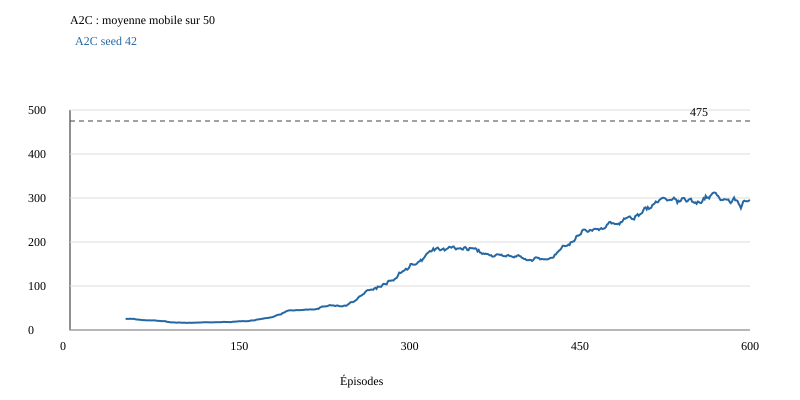

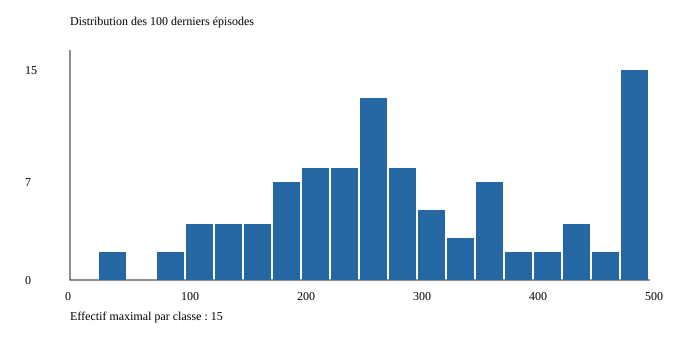

In [9]:
display(new PolicySvg(Charts.Lines("A2C : moyenne mobile sur 50", new Dictionary<string, double[]> { ["A2C seed 42"] = rewardsA2c }, 50, 475)));
display(new PolicySvg(Charts.Histogram(rewardsA2c.TakeLast(100).ToArray())));

## 5. Comparaison multi-graines A2C / REINFORCE

Cinq graines {42,0,1,7,99}, 400 épisodes par algorithme, même architecture et taux d’apprentissage. REINFORCE utilise les retours actualisés bruts sans baseline ni normalisation. On rapporte les finales sur 50 épisodes, leur médiane et leur IQR, ainsi que le premier franchissement de la moyenne mobile 150. La médiane de temps est conditionnelle aux graines qui atteignent ce seuil.


In [10]:
// Les deux conditions partagent le budget et les cinq graines.
var seeds = new[]
{
    42,
    0,
    1,
    7,
    99
};
// Former un couple A2C/REINFORCE par graine et garder chaque série entière.
var a2cRuns = new Dictionary<int, double[]>();
var reinforceRuns = new Dictionary<int, double[]>();
foreach (int seed in seeds)
{
    a2cRuns[seed] = Learning.TrainA2C(400, seed, false);
    reinforceRuns[seed] = Learning.TrainA2C(400, seed, true);
    Console.WriteLine($"graine {seed, 2} : A2C {a2cRuns[seed].TakeLast(50).Average():F1} ; REINFORCE {reinforceRuns[seed].TakeLast(50).Average():F1}");
}

int? FirstThreshold(double[] curve)
{
    var m = Charts.Moving(curve, 50);
    // Une graine qui n'atteint jamais 150 ne fournit aucune date de franchissement.
    int i = Array.FindIndex(m, x => x >= 150);
    return i < 0 ? null : i + 50;
}

foreach (var(name, runs)in new[]
{
    ("A2C", a2cRuns),
    ("REINFORCE", reinforceRuns)
}

)
{
    // Une valeur par graine mesure l'incertitude entre répétitions indépendantes.
    var finals = seeds.Select(s => runs[s].TakeLast(50).Average()).ToArray();
    var reached = seeds.Select(s => FirstThreshold(runs[s])).Where(x => x.HasValue).Select(x => (double)x!.Value).ToArray();
    Console.WriteLine($"{name} : médiane {Charts.Quantile(finals, .5):F1}, IQR [{Charts.Quantile(finals, .25):F1}, {Charts.Quantile(finals, .75):F1}]" +
        $", seuil 150 : {reached.Length}/5, médiane conditionnelle {(reached.Length == 0 ? "non atteint" : Charts.Quantile(reached, .5).ToString("F0"))}.");
}

graine 42 : A2C 163.1 ; REINFORCE 69.2


graine  0 : A2C 205.8 ; REINFORCE 115.4


graine  1 : A2C 253.3 ; REINFORCE 196.0


graine  7 : A2C 192.6 ; REINFORCE 24.1


graine 99 : A2C 175.2 ; REINFORCE 145.9


A2C : médiane 192.6, IQR [175.2, 205.8], seuil 150 : 5/5, médiane conditionnelle 351.


REINFORCE : médiane 115.4, IQR [69.2, 145.9], seuil 150 : 2/5, médiane conditionnelle 383.


### Lecture

Comparer l’IQR des finales mesure la dispersion entre entraînements, pas directement la variance du gradient. Avec cinq graines et d’autres différences de perte (notamment l’entropie), cette comparaison ne prouve pas à elle seule la causalité du critic. Les graines n’atteignant pas 150 restent dans le dénominateur.


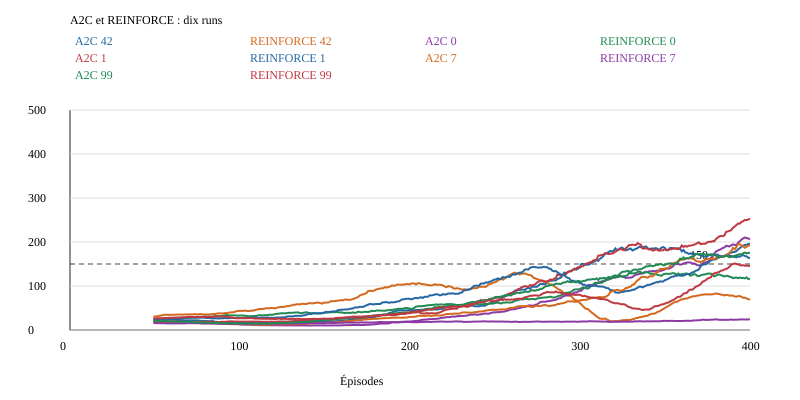

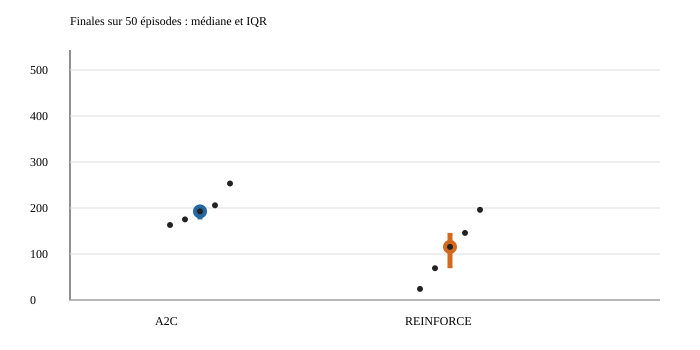

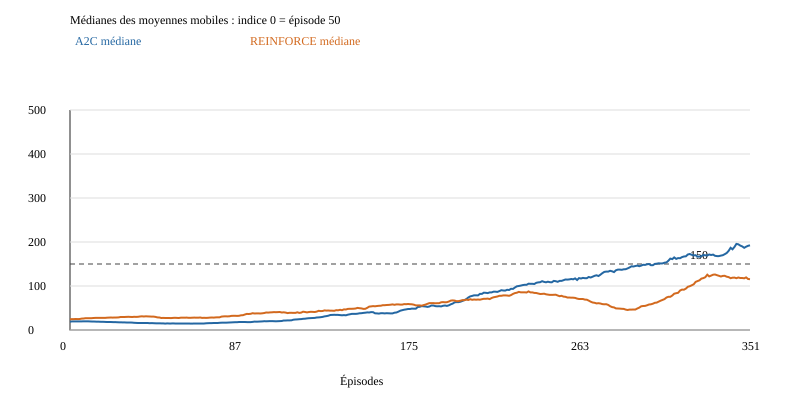

In [11]:
// Comparer les courbes individuelles, puis les médianes et IQR inter-graines.
var allCurves = new Dictionary<string, double[]>();
foreach (int seed in seeds)
{
    allCurves[$"A2C {seed}"] = a2cRuns[seed];
    allCurves[$"REINFORCE {seed}"] = reinforceRuns[seed];
}

display(new PolicySvg(Charts.Lines("A2C et REINFORCE : dix runs", allCurves, 50, 150)));
var finalsByAlgorithm = new Dictionary<string, double[]> {
    ["A2C"] = seeds.Select(s => a2cRuns[s].TakeLast(50).Average()).ToArray(),
    ["REINFORCE"] = seeds.Select(s => reinforceRuns[s].TakeLast(50).Average()).ToArray()
};
display(new PolicySvg(Charts.Distribution("Finales sur 50 épisodes : médiane et IQR", finalsByAlgorithm)));
var maA2c = seeds.Select(s => Charts.Moving(a2cRuns[s], 50)).ToArray();
var maReinforce = seeds.Select(s => Charts.Moving(reinforceRuns[s], 50)).ToArray();
var medianCurves = new Dictionary<string, double[]>
{
    ["A2C médiane"] = Enumerable.Range(0, maA2c[0].Length).Select(i => Charts.Quantile(maA2c.Select(c => c[i]).ToArray(), .5)).ToArray(),
    ["REINFORCE médiane"] = Enumerable.Range(0, maReinforce[0].Length).Select(i => Charts.Quantile(maReinforce.Select(c => c[i]).ToArray(), .5)).ToArray()
};
display(new PolicySvg(Charts.Lines("Médianes des moyennes mobiles : indice 0 = épisode 50", medianCurves, 1, 150)));

### Exercice 2 — Comparer les algorithmes

Implémentez un protocole alternatif à budget et graines communs ; retournez les deux courbes pour les superposer et comparez le taux d’atteinte du seuil.


In [12]:
#nullable enable
(double[] a2c, double[] reinforce)? ComparerAlgorithmes(int episodes, int seed)
{
    return null; // TODO : appeler ou réimplémenter les deux entraînements au même budget
}

var comparaison = ComparerAlgorithmes(400, 42);
if (comparaison is null)
    Console.WriteLine("Exercice à compléter : comparaison appariée.");
else if (comparaison.Value.a2c.Length != 400 || comparaison.Value.reinforce.Length != 400)
    throw new Exception("Budget incorrect");
else
    Console.WriteLine($"Finales : {comparaison.Value.a2c.TakeLast(50).Average():F1} et {comparaison.Value.reinforce.TakeLast(50).Average():F1}");

Exercice à compléter : comparaison appariée.


## 6. Bonus d’entropie

$H(\pi)=-\sum_a\pi(a|s)\log\pi(a|s)$ augmente lorsque la distribution est plus diffuse. Son coefficient équilibre exploration et rendement ; il ne garantit pas une politique optimale. Une ablation de ce coefficient aide à distinguer son effet de celui du critic.

### Exercice 3 — Ablation

Entraînez avec coefficients 0, 0,01, 0,05 et 0,1, puis comparez les courbes et l’entropie.


In [13]:
#nullable enable
Dictionary<double, (double[] rewards, double[] entropies)>? AblationEntropie(int episodes, int seed)
{
    return null; // TODO : entraîner avec Learning.TrainA2C et son callback onEntropy
}

var entropyRuns = AblationEntropie(400, 42);
if (entropyRuns is null)
    Console.WriteLine("Exercice à compléter : ablation d’entropie.");
else if (entropyRuns.Count != 4 || entropyRuns.Values.Any(x => x.rewards.Length != 400 || x.entropies.Length != 400))
    throw new Exception("Quatre paires de courbes de 400 épisodes attendues");
else
    Console.WriteLine($"Configurations mesurées : {entropyRuns.Count}");

Exercice à compléter : ablation d’entropie.


## 7. Ouverture et à retenir

A3C distribue l’apprentissage ; PPO réutilise les données avec un objectif clippé ; SAC optimise l’entropie dans un cadre adapté aux actions continues ; TD3 utilise deux critiques. L’avantage A2C est une différence entre retour et valeur, non une garantie de succès. La distinction terminaison/troncature détermine le bootstrap.

## Vérifiez votre compréhension

Pourquoi la dispersion des finales sur cinq graines ne suffit-elle pas à établir une réduction de variance du gradient ?

<details><summary>Éléments de réponse</summary>

Elle mesure les performances de cinq entraînements finis. Le gradient lui-même n’est pas échantillonné dans ce tableau et les pertes diffèrent aussi par le bonus d’entropie.

</details>

## Pour aller plus loin

Williams (1992), *Simple Statistical Gradient-Following Algorithms* ; Konda et Tsitsiklis (2003), *On Actor-Critic Algorithms* ; Mnih et al. (2016), *Asynchronous Methods for Deep Reinforcement Learning* ; Sutton et Barto (2018), chapitre 13.
